In [52]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, root_mean_squared_error, mean_absolute_error

In [53]:
df=pd.read_csv('HousingData.csv')
df.head()

,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,B,LSTAT,MEDV
0,0.00632,18.0,2.31,0.0,0.538,6.575,65.2,4.0900,1,296,15.3,396.90,4.98,24.0
1,0.02731,0.0,7.07,0.0,0.469,6.421,78.9,4.9671,2,242,17.8,396.90,9.14,21.6
2,0.02729,0.0,7.07,0.0,0.469,7.185,61.1,4.9671,2,242,17.8,392.83,4.03,34.7
3,0.03237,0.0,2.18,0.0,0.458,6.998,45.8,6.0622,3,222,18.7,394.63,2.94,33.4
4,0.06905,0.0,2.18,0.0,0.458,7.147,54.2,6.0622,3,222,18.7,396.90,NaN,36.2


In [54]:
df=df.rename(columns={'MEDV':'Price'})

In [55]:
df.isnull().sum()

CRIM       20
ZN         20
INDUS      20
CHAS       20
NOX         0
RM          0
AGE        20
DIS         0
RAD         0
TAX         0
PTRATIO     0
B           0
LSTAT      20
Price       0
dtype: int64

In [56]:
df=df.fillna(df.mean())

In [57]:
df.head()

,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,B,LSTAT,Price
0,0.00632,18.0,2.31,0.0,0.538,6.575,65.2,4.0900,1,296,15.3,396.90,4.980000,24.0
1,0.02731,0.0,7.07,0.0,0.469,6.421,78.9,4.9671,2,242,17.8,396.90,9.140000,21.6
2,0.02729,0.0,7.07,0.0,0.469,7.185,61.1,4.9671,2,242,17.8,392.83,4.030000,34.7
3,0.03237,0.0,2.18,0.0,0.458,6.998,45.8,6.0622,3,222,18.7,394.63,2.940000,33.4
4,0.06905,0.0,2.18,0.0,0.458,7.147,54.2,6.0622,3,222,18.7,396.90,12.715432,36.2


In [58]:
x=df.drop('Price', axis=1)
y=df['Price']

In [80]:
x.shape

(506, 13)

In [78]:
y.shape

(506,)

In [72]:
xtrain, xtest, ytrain, ytest=train_test_split(x, y, test_size=0.12, random_state=42)

In [73]:
model=LinearRegression()
model.fit(xtrain, ytrain)
y_pred=model.predict(xtest)

In [81]:
y_pred.shape

(61,)

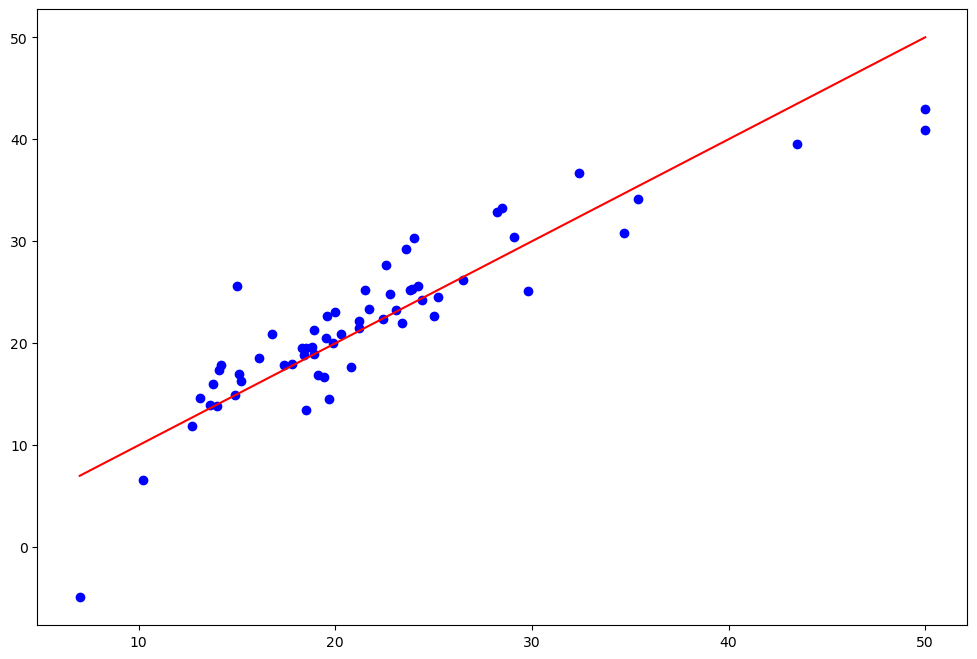

In [96]:
plt.figure(figsize=(12,8))
plt.scatter(ytest,y_pred, color="blue")
plt.plot([min(ytest), max(ytest)], [min(ytest), max(ytest)], color='red')

In [75]:
mae=mean_absolute_error(ytest, y_pred)
rmse=root_mean_squared_error(ytest,y_pred)
r2=r2_score(ytest, y_pred)
print(mae, rmse, r2)

2.628922376067444 3.6555502569855363 0.7969056086158027
